In [1]:
# import  python libraries for initial data processing

import matplotlib.pyplot as plt
import numpy as np
import lightkurve as lk
from lightkurve import search_targetpixelfile
import astropy
from astropy.io import fits

In [2]:
pixelfile = search_targetpixelfile("KIC 8462852", quarter=16).download();


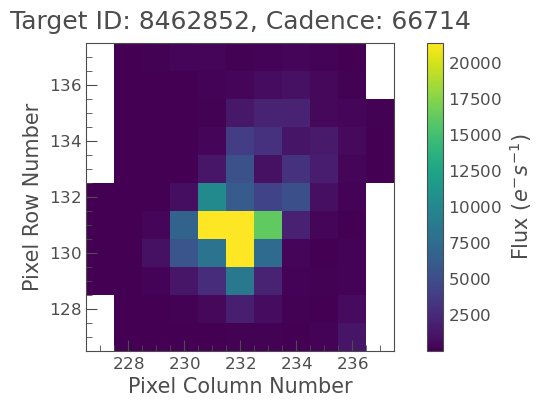

In [3]:
pixelfile.plot(frame=1);

In [4]:
# function that returns a lightcurve object (flux, the number of photons detected over time)

lc = pixelfile.to_lightcurve(aperture_mask='all');

In [10]:
lc.time

<Time object: scale='tdb' format='bkjd' value=[1472.11777934 1472.13821223 1472.15864492 ... 1557.91762194 1557.9380561
 1557.95849016]>

In [11]:
lc.flux

<Quantity [258645.03, 258660.05, 258690.08, ..., 258948.84, 258884.66,
           258865.6 ] electron / s>

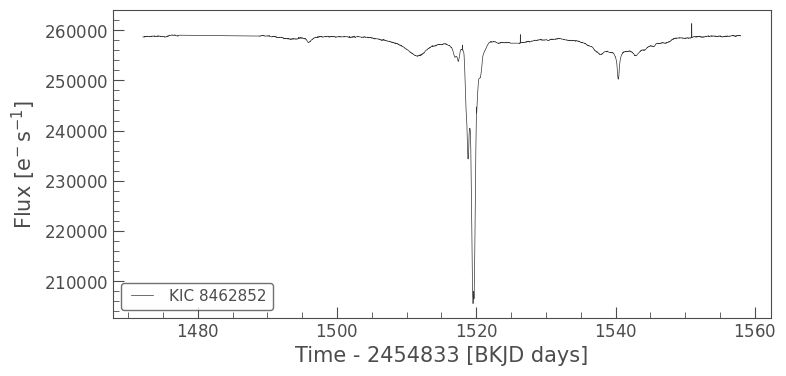

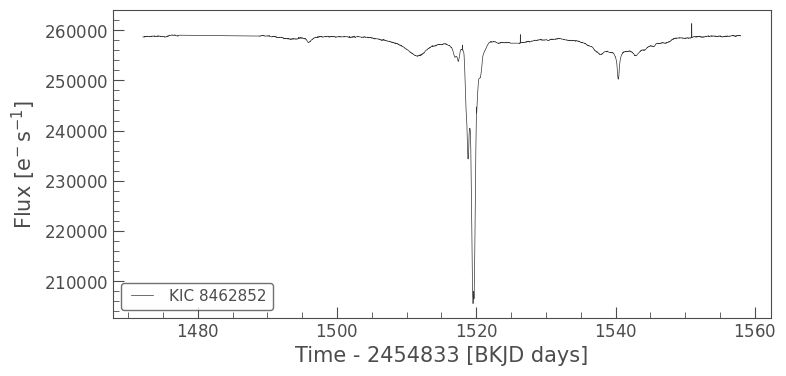

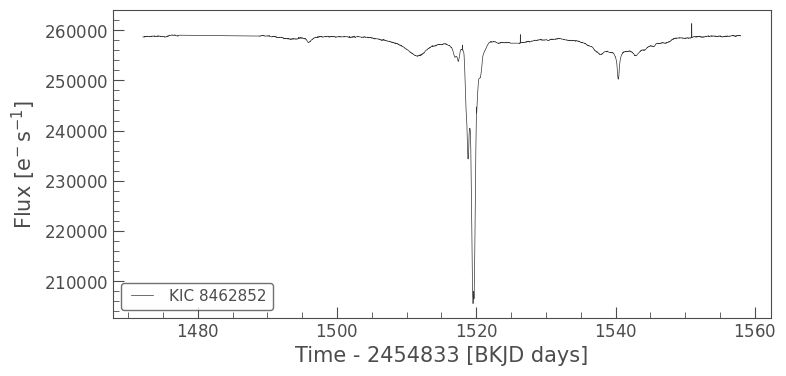

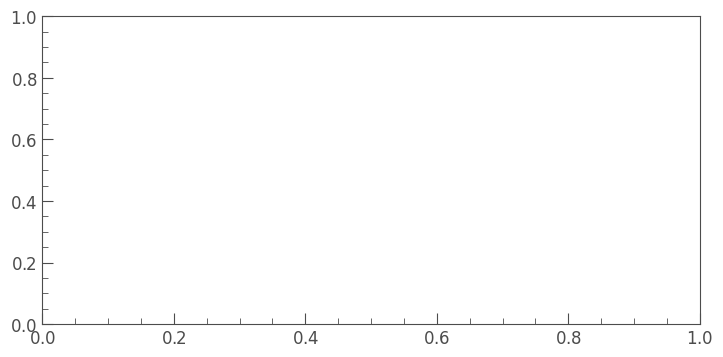

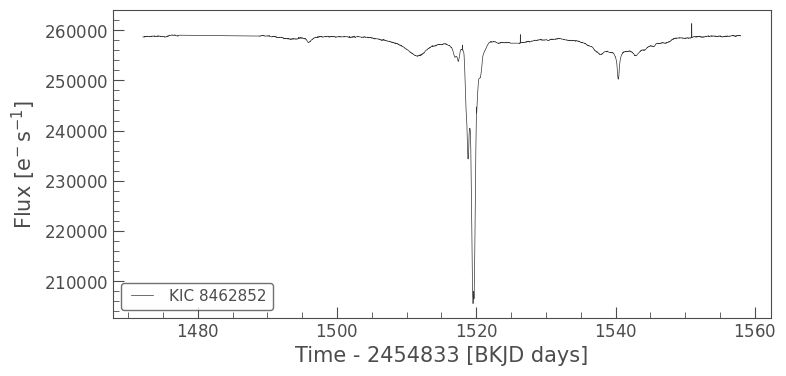

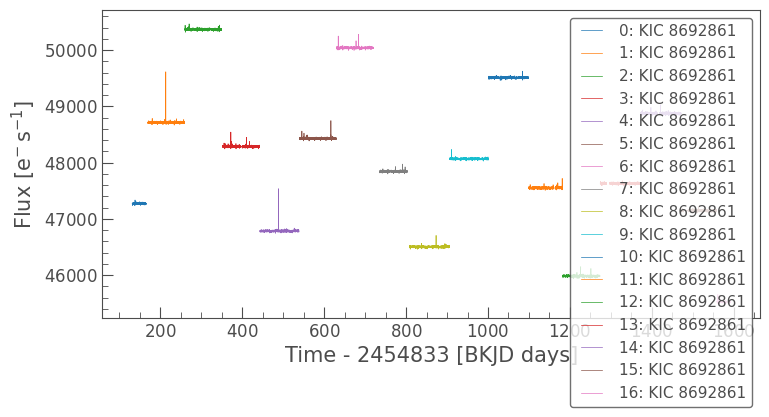

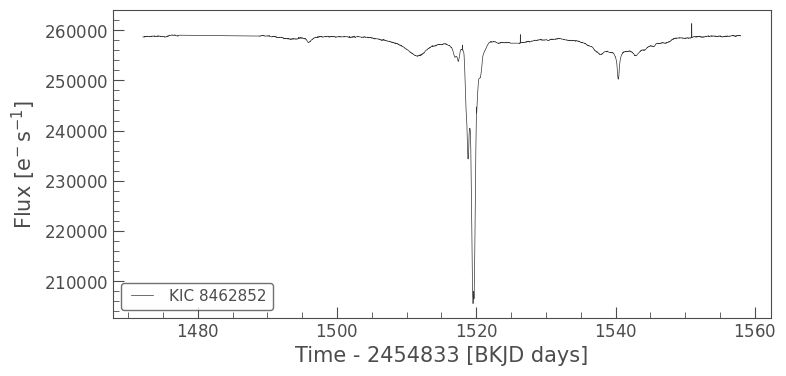

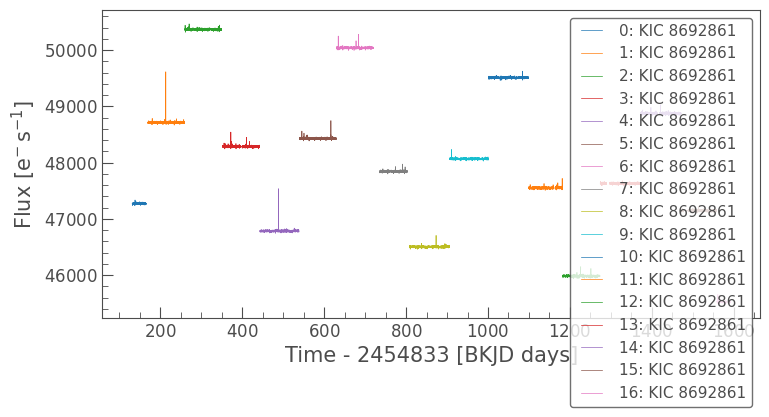

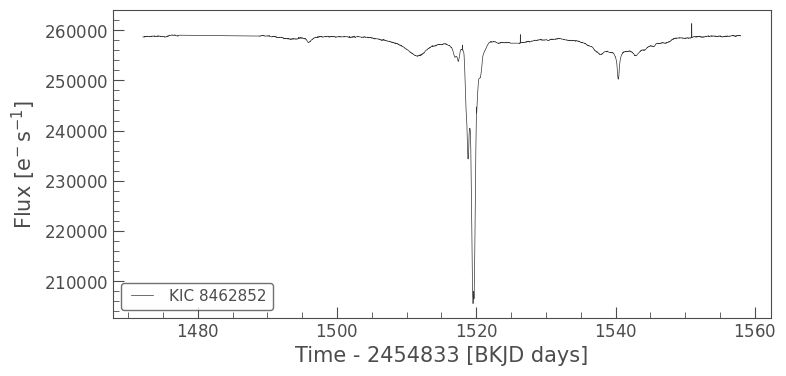

In [19]:
lc.plot();
plt.show()

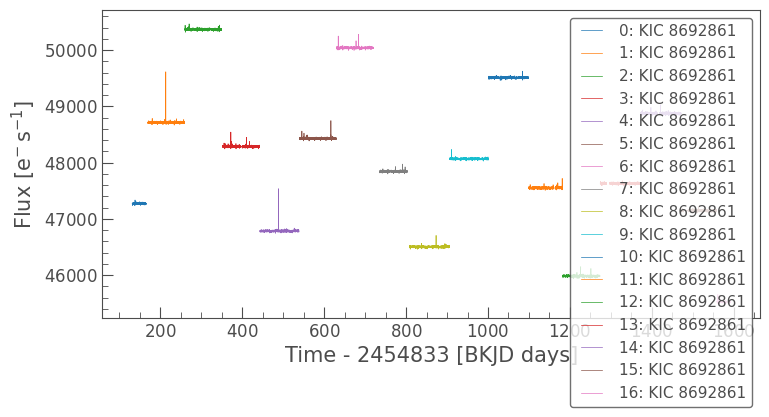

In [20]:
search_result = lk.search_lightcurve('Kepler-69', author='Kepler', cadence='long')
# Download all available Kepler light curves
lc_collection = search_result.download_all()
lc_collection.plot();
plt.show()


In [21]:
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 01,2009,Kepler,1800,kplr008692861,0.0
1,Kepler Quarter 02,2009,Kepler,1800,kplr008692861,0.0
2,Kepler Quarter 03,2009,Kepler,1800,kplr008692861,0.0
3,Kepler Quarter 04,2010,Kepler,1800,kplr008692861,0.0
4,Kepler Quarter 05,2010,Kepler,1800,kplr008692861,0.0
5,Kepler Quarter 06,2010,Kepler,1800,kplr008692861,0.0
6,Kepler Quarter 07,2010,Kepler,1800,kplr008692861,0.0
7,Kepler Quarter 08,2011,Kepler,1800,kplr008692861,0.0
8,Kepler Quarter 09,2011,Kepler,1800,kplr008692861,0.0


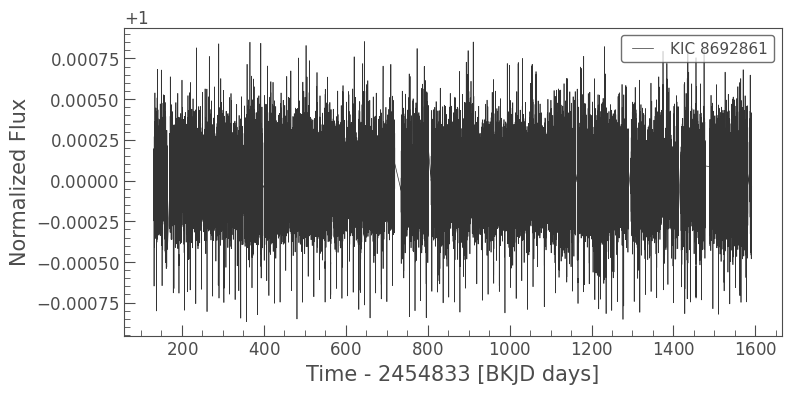

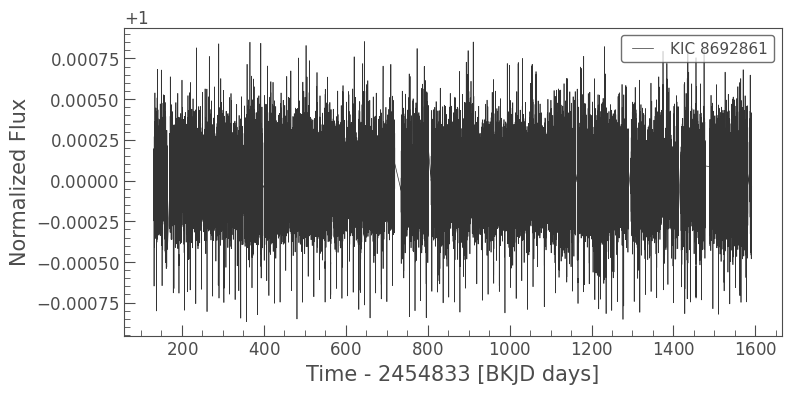

In [23]:
# Flatten the light curve

lc = lc_collection.stitch().flatten(window_length=901).remove_outliers()
lc.plot();
plt.show()


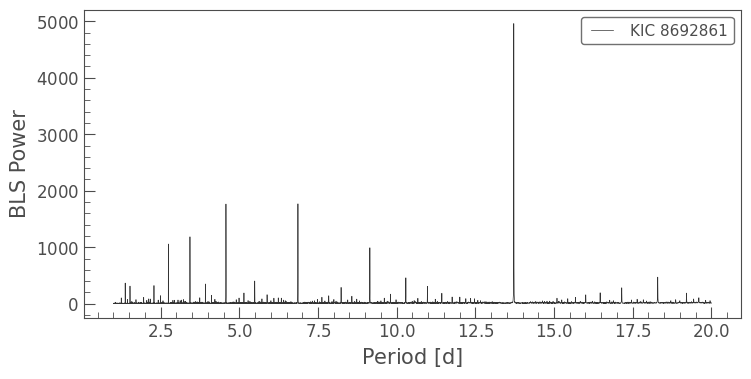

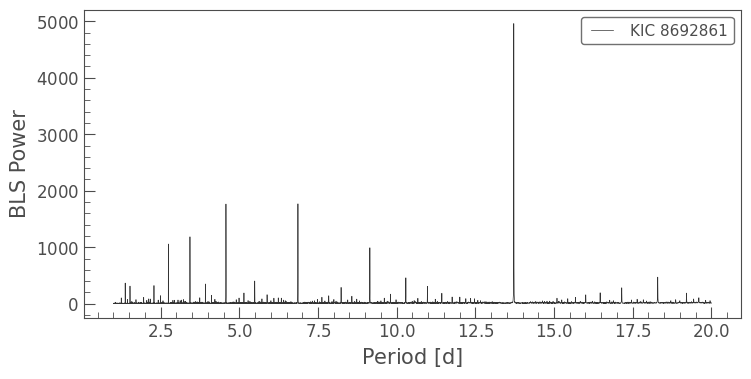

In [25]:
import numpy as np
# Create array of periods to search
period = np.linspace(1, 20, 10000)
# Create a BLSPeriodogram
bls = lc.to_periodogram(method='bls', period=period, frequency_factor=500);
bls.plot();
plt.show()



In [26]:
planet_b_period = bls.period_at_max_power
planet_b_t0 = bls.transit_time_at_max_power
planet_b_dur = bls.duration_at_max_power

# Check the value for period
planet_b_period



<Quantity 13.72177218 d>

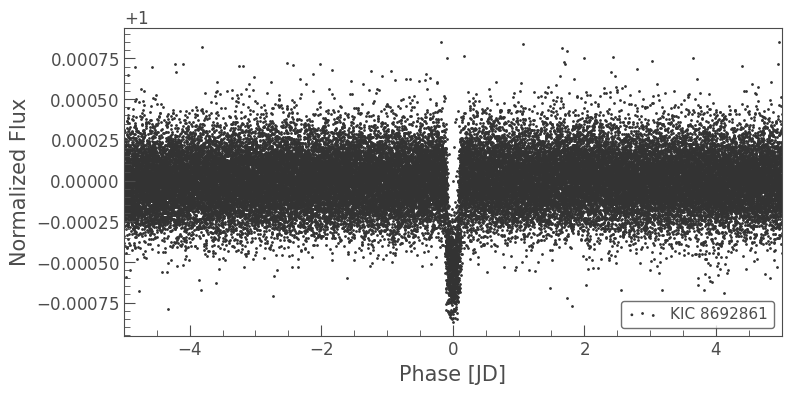

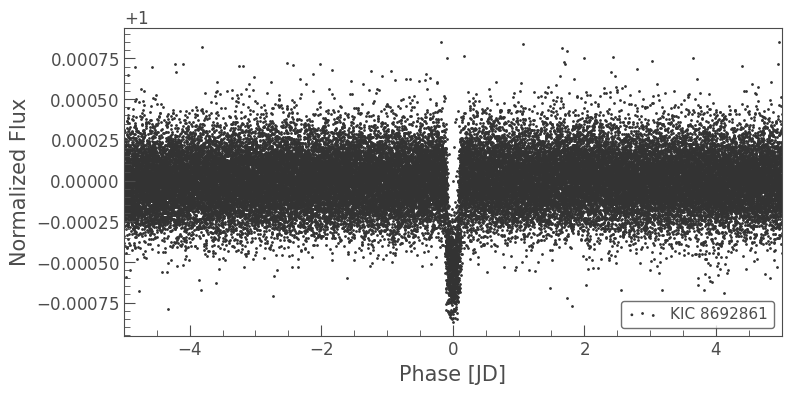

In [28]:
ax = lc.fold(period=planet_b_period, epoch_time=planet_b_t0).scatter()
ax.set_xlim(-5, 5);
plt.show()


